# TV1 – GIAI ĐOẠN 1: APRIORI – BẢN SỬA KIỂM TRA ĐẦU VÀO
**Đề tài:** Phân tích giỏ hàng siêu thị và xây dựng gợi ý mua kèm.

## 1. Nguyên lý và thước đo
Apriori tìm các tập mặt hàng có support đạt ngưỡng. Thuật toán xét tập 1 phần tử, sinh ứng viên lớn hơn và cắt tỉa: nếu một tập không phổ biến thì mọi tập chứa nó cũng không phổ biến. Từ các tập phổ biến, sinh luật $X\rightarrow Y$, với $X,Y$ khác rỗng và không giao nhau.

$$support(X\rightarrow Y)=\frac{n(X\cup Y)}{N}$$
$$confidence(X\rightarrow Y)=\frac{support(X\cup Y)}{support(X)}$$
$$lift(X\rightarrow Y)=\frac{confidence(X\rightarrow Y)}{support(Y)}$$

$N$ là số **giỏ hàng**, không phải số dòng CSV. Support 0.003 nghĩa là 0.3%, không phải 3%.

- Support: mức độ xuất hiện đồng thời; confidence: tỷ lệ có Y trong các giỏ có X.
- Lift > 1: đồng xuất hiện nhiều hơn mức kỳ vọng theo giả định độc lập; lift gần 1: tín hiệu mua kèm yếu; lift < 1: đồng xuất hiện ít hơn kỳ vọng.
- Lift cao trên rất ít giỏ có thể không ổn định. Không diễn giải luật thành quan hệ nhân quả hoặc cam kết hiệu quả bán hàng.


In [1]:
import os, io, json, math, time, hashlib, platform, shutil, tempfile
from pathlib import Path
from collections import Counter
from itertools import combinations
from fractions import Fraction
from decimal import Decimal, ROUND_CEILING
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
# Mỗi lần chạy có thư mục riêng để không trộn kết quả của các lần chạy khác nhau.
OUT = Path(tempfile.mkdtemp(prefix='TV1_Customers_Apriori_', dir='.')).resolve()
def nhan_xet(text): display(Markdown('**Nhận xét:** ' + text))
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| NumPy:', np.__version__)


Python: 3.13.16 | pandas: 2.2.3 | NumPy: 2.1.3


## 2. Đọc và chuẩn bị dữ liệu có kiểm tra
Cần các cột `Member_number`, `Date`, `itemDescription`. `month` là trường dẫn xuất, có thể thiếu và sẽ được tạo từ Date.

Chấp nhận ngày `YYYY-MM-DD`, `DD-MM-YYYY` hoặc `DD/MM/YYYY`; dạng có năm ở cuối được hiểu theo **ngày–tháng–năm**, không đoán tháng trước ngày. CSV đọc thành chuỗi là bình thường.

Tự xử lý các thao tác đã thống nhất cho giỏ nhị phân: strip tên hàng; giữ một dòng mỗi khách hàng–ngày–sản phẩm; tạo lại month từ Date. Các dòng lặp không được diễn giải là gian lận hay lỗi nghiệp vụ. Ngày sai, mã không nguyên dương, tên rỗng hoặc ký tự điều khiển sẽ được báo cụ thể và không bị âm thầm loại bỏ.


In [2]:
local_file = os.environ.get('TV1_DATA_FILE')
if local_file:
    filename = Path(local_file).name
    raw_bytes = Path(local_file).read_bytes()
else:
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Vui lòng chọn đúng một file CSV dữ liệu mua hàng.')
    filename, raw_bytes = next(iter(uploaded.items()))
file_sha256 = hashlib.sha256(raw_bytes).hexdigest()
df = pd.read_csv(io.BytesIO(raw_bytes))
required = ['Member_number', 'Date', 'itemDescription']
if not set(required).issubset(df.columns):
    raise ValueError(f'File cần các cột: {required}. Các cột hiện có: {list(df.columns)}')
if df.empty:
    raise ValueError('File không có bản ghi.')
print('File:', filename, '| Số dòng/cột:', df.shape)
print('SHA-256:', file_sha256)
display(df.head())
display(pd.DataFrame({'thuoc_tinh': df.columns, 'kieu_doc_tu_csv': df.dtypes.astype(str).values}))


Saving customers_clean_apriori.csv to customers_clean_apriori (1).csv
File: customers_clean_apriori (1).csv | Số dòng/cột: (38006, 4)
SHA-256: 3545def373da34add7d82e827ae6accd2e01419f3258f1e44641cffea2b5c1e1


,Member_number,Date,itemDescription,month
0,1808,2015-07-21,tropical fruit,2015-07
1,2552,2015-01-05,whole milk,2015-01
2,2300,2015-09-19,pip fruit,2015-09
3,1187,2015-12-12,other vegetables,2015-12
4,3037,2015-02-01,whole milk,2015-02


,thuoc_tinh,kieu_doc_tu_csv
0,Member_number,int64
1,Date,object
2,itemDescription,object
3,month,object


In [3]:
def prepare_input(data):
    required_cols = ['Member_number', 'Date', 'itemDescription']
    missing_cols = sorted(set(required_cols) - set(data.columns))
    if missing_cols:
        raise ValueError('Thiếu cột bắt buộc: ' + ', '.join(missing_cols))
    if data.empty:
        raise ValueError('File không có dòng dữ liệu.')
    raw = data.copy().reset_index(drop=True)
    date_text = raw['Date'].astype('string').str.strip()
    parsed = pd.Series(pd.NaT, index=raw.index, dtype='datetime64[ns]')
    for pattern, fmt in [(r'\d{4}-\d{2}-\d{2}', '%Y-%m-%d'),
                         (r'\d{2}-\d{2}-\d{4}', '%d-%m-%Y'),
                         (r'\d{2}/\d{2}/\d{4}', '%d/%m/%Y')]:
        mask = date_text.str.fullmatch(pattern, na=False)
        parsed.loc[mask] = pd.to_datetime(date_text.loc[mask], format=fmt, errors='coerce')
    numeric_ids = pd.to_numeric(raw['Member_number'], errors='coerce')
    labels = raw['itemDescription'].astype('string')
    trimmed = labels.str.strip()
    flags = {
        'Ngày thiếu/sai hoặc định dạng chưa hỗ trợ': parsed.isna(),
        'Mã khách hàng phải là số nguyên dương hợp lệ': (
            numeric_ids.isna() | ~np.isfinite(numeric_ids) | numeric_ids.le(0)
            | numeric_ids.mod(1).ne(0) | numeric_ids.ge(2**63)),
        'Tên sản phẩm thiếu/rỗng/không phải chuỗi': (
            trimmed.isna() | trimmed.eq('').fillna(True)
            | ~raw['itemDescription'].map(lambda x: isinstance(x, str))),
        'Tên sản phẩm chứa ký tự điều khiển': labels.str.contains(r'[\x00-\x1f\x7f]', regex=True, na=False),
    }
    errors = pd.DataFrame(flags).fillna(True)
    invalid = errors.any(axis=1)
    if invalid.any():
        details = raw.loc[invalid, required_cols].copy()
        details.insert(0, 'dong_du_lieu', details.index + 1)
        details['ly_do'] = errors.loc[invalid].apply(lambda row: '; '.join(row.index[row]), axis=1)
        display(details.head(20))
        counts = errors.sum()
        explanation = '; '.join(f'{label}: {int(count)}' for label, count in counts.items() if count)
        raise ValueError(f'Có {int(invalid.sum())} dòng chưa thể dùng. {explanation}. Xem bảng dòng lỗi phía trên.')
    work = raw.copy()
    work['Member_number'] = numeric_ids.astype('int64')
    work['Date'] = parsed
    work['itemDescription'] = trimmed
    expected_month = parsed.dt.strftime('%Y-%m')
    old_month = raw['month'].astype('string') if 'month' in raw else pd.Series(pd.NA, index=raw.index, dtype='string')
    changed_months = int(old_month.ne(expected_month).fillna(True).sum())
    work['month'] = expected_month
    trimmed_rows = int(labels.ne(trimmed).fillna(False).sum())
    repeated = work.duplicated(['Member_number', 'Date', 'itemDescription'])
    removed = int(repeated.sum())
    work = work.loc[~repeated].reset_index(drop=True)
    # Chuẩn hóa trường thiết yếu đã đủ; không chặn bởi khác biệt hoa/thường có thể hợp lệ.
    unique_labels = work['itemDescription'].drop_duplicates()
    canonical = unique_labels.str.casefold().str.replace(r'\s+', ' ', regex=True)
    variants = pd.DataFrame({'nhan': unique_labels, 'dang_so_sanh': canonical})
    variants = variants.groupby('dang_so_sanh')['nhan'].agg(list)
    variants = variants[variants.map(len).gt(1)]
    quality = pd.DataFrame([
        ('Số dòng', len(raw), len(work)),
        ('Ô thiếu trong 3 trường thiết yếu', int(raw[required_cols].isna().sum().sum()), 0),
        ('Ngày không hợp lệ', 0, 0),
        ('Mã khách hàng không hợp lệ', 0, 0),
        ('Tên thiếu/rỗng/không hợp lệ', 0, 0),
        ('Dòng tên có khoảng trắng đầu/cuối', trimmed_rows, 0),
        ('Dòng lặp theo khách hàng–ngày–sản phẩm sau strip', removed, 0),
        ('month thiếu/khác tháng rút ra từ Date', changed_months, 0),
    ], columns=['kiem_tra', 'truoc_chuan_bi', 'sau_chuan_bi'])
    log = {'input_rows':len(raw), 'output_rows':len(work), 'trimmed_names':trimmed_rows,
           'removed_repeated_items':removed, 'month_created_or_corrected':changed_months,
           'possible_label_variant_groups':len(variants)}
    return work, quality, log, variants

# Đây là kiểm tra trực tiếp từ df hiện tại; kết quả cũ của một lần upload không được dùng lại.
_, quality_preview, preparation_preview, variant_preview = prepare_input(df)
display(quality_preview)
if not variant_preview.empty:
    print('Các nhãn có thể là biến thể; giữ nguyên, cần đối chiếu nghiệp vụ:')
    display(variant_preview.to_frame())


,kiem_tra,truoc_chuan_bi,sau_chuan_bi
0,Số dòng,38006,38006
1,Ô thiếu trong 3 trường thiết yếu,0,0
2,Ngày không hợp lệ,0,0
3,Mã khách hàng không hợp lệ,0,0
4,Tên thiếu/rỗng/không hợp lệ,0,0
5,Dòng tên có khoảng trắng đầu/cuối,0,0
6,Dòng lặp theo khách hàng–ngày–sản phẩm sau strip,0,0
7,month thiếu/khác tháng rút ra từ Date,0,0


## 3. Tạo giỏ hàng từ dữ liệu đã chuẩn bị
Hàm chuẩn bị được gọi trực tiếp trên `df` hiện tại nên không phụ thuộc các cờ kiểm tra cũ. Tự xử lý các vấn đề định dạng đã nêu ở mục 2, sau đó gom theo `(Member_number, Date)`.

Một sản phẩm trong mỗi giỏ chỉ tính có mặt một lần. Giữ mọi giỏ khác nhau, dù danh sách hàng giống nhau. Cột month không dùng làm khóa giỏ. Không có mã hóa đơn nên nhiều lần mua trong ngày có thể nằm chung một giỏ đại diện.


In [4]:
work, quality, preparation_log, variant_groups = prepare_input(df)
dates = work['Date']
missing_table = pd.DataFrame({'cot':df.columns, 'so_thieu_dau_vao':df.isna().sum().values})
display(quality)
print('Thao tác chuẩn bị:', preparation_log)
if len(variant_groups):
    print('Nhãn có thể là biến thể được giữ nguyên:')
    display(variant_groups.to_frame())
quality_text = (f'Đầu vào {len(df):,} dòng; sau chuẩn bị {len(work):,} dòng. '
                f'Cắt khoảng trắng ở {preparation_log["trimmed_names"]:,} dòng; '
                f'bỏ {preparation_log["removed_repeated_items"]:,} bản ghi lặp trong giỏ; '
                f'tạo/sửa month ở {preparation_log["month_created_or_corrected"]:,} dòng. ')
quality_verdict = 'Dữ liệu sau chuẩn bị đạt các kiểm tra bắt buộc để tạo giỏ.'
grouped = work.groupby(['Member_number', 'Date'], sort=True)['itemDescription'].agg(list)
transactions = [tuple(sorted(set(basket))) for basket in grouped]
N = len(transactions)
items = sorted(set().union(*map(set, transactions)))
canonical = json.dumps(transactions, ensure_ascii=False, separators=(',', ':'))
transaction_sha256 = hashlib.sha256(canonical.encode()).hexdigest()
basket_sizes = pd.Series([len(t) for t in transactions])
input_summary = pd.DataFrame({'chi_tieu':[
    'Số dòng đầu vào', 'Số dòng sau chuẩn bị', 'Số khách hàng', 'Số giỏ', 'Số mặt hàng',
    'Ngày đầu', 'Ngày cuối', 'Mặt hàng phân biệt trung bình/giỏ', 'Mặt hàng phân biệt lớn nhất/giỏ'],
    'gia_tri':[len(df),len(work),work.Member_number.nunique(),N,len(items),
               dates.min().strftime('%d/%m/%Y'),dates.max().strftime('%d/%m/%Y'),
               round(basket_sizes.mean(),4),int(basket_sizes.max())]})
display(input_summary)
display(pd.DataFrame({'khach_hang_ngay':list(grouped.index[:5]), 'items':transactions[:5]}))
nhan_xet(quality_text + f'Mẫu số support là {N:,} giỏ. File CSV tải lên không bị ghi đè.')
print('SHA-256 transaction:',transaction_sha256)


,kiem_tra,truoc_chuan_bi,sau_chuan_bi
0,Số dòng,38006,38006
1,Ô thiếu trong 3 trường thiết yếu,0,0
2,Ngày không hợp lệ,0,0
3,Mã khách hàng không hợp lệ,0,0
4,Tên thiếu/rỗng/không hợp lệ,0,0
5,Dòng tên có khoảng trắng đầu/cuối,0,0
6,Dòng lặp theo khách hàng–ngày–sản phẩm sau strip,0,0
7,month thiếu/khác tháng rút ra từ Date,0,0


Thao tác chuẩn bị: {'input_rows': 38006, 'output_rows': 38006, 'trimmed_names': 0, 'removed_repeated_items': 0, 'month_created_or_corrected': 0, 'possible_label_variant_groups': 0}


,chi_tieu,gia_tri
0,Số dòng đầu vào,38006
1,Số dòng sau chuẩn bị,38006
2,Số khách hàng,3898
3,Số giỏ,14963
4,Số mặt hàng,167
5,Ngày đầu,01/01/2014
6,Ngày cuối,30/12/2015
7,Mặt hàng phân biệt trung bình/giỏ,2.54
8,Mặt hàng phân biệt lớn nhất/giỏ,10


,khach_hang_ngay,items
0,"(1000, 2014-06-24 00:00:00)","(pastry, salty snack, whole milk)"
1,"(1000, 2015-03-15 00:00:00)","(sausage, semi-finished bread, whole milk, yogurt)"
2,"(1000, 2015-05-27 00:00:00)","(pickled vegetables, soda)"
3,"(1000, 2015-07-24 00:00:00)","(canned beer, misc. beverages)"
4,"(1000, 2015-11-25 00:00:00)","(hygiene articles, sausage)"


**Nhận xét:** Đầu vào 38,006 dòng; sau chuẩn bị 38,006 dòng. Cắt khoảng trắng ở 0 dòng; bỏ 0 bản ghi lặp trong giỏ; tạo/sửa month ở 0 dòng. Mẫu số support là 14,963 giỏ. File CSV tải lên không bị ghi đè.

SHA-256 transaction: 7910a17405595931e73ac896e71ba1256b1d4b2596f6f5350e7535ce77c99137


## 4. Kiểm tra danh sách ngưỡng sup và conf
**`SUPPORTS` (sup)** là danh sách tỷ lệ giỏ chứa đồng thời tập sản phẩm cần đạt. Ví dụ `0.003 = 0.3%`, không phải 3%. Số giỏ tối thiểu bằng $\lceil N \times min\_support\rceil$.

**`CONFIDENCES` (conf)** là danh sách tỷ lệ có vế phải **trong số giỏ có vế trái**. Ví dụ `0.10 = 10%`: trong 100 giỏ chứa X cần ít nhất 10 giỏ chứa cả X và Y. Không lấy 10% tổng số giỏ để giải thích confidence.

Danh sách thăm dò chính:
```python
SUPPORTS = [0.001, 0.003, 0.005, 0.0075, 0.010]  # 0.1%, 0.3%, 0.5%, 0.75%, 1%
CONFIDENCES = [0.08, 0.10, 0.12, 0.15]           # 8%, 10%, 12%, 15%
```
**5 × 4 = 20 cấu hình**, không phải 5 + 4. Các giá trị là ngưỡng tự chọn để khảo sát, không phải “đáp án đúng” cố định cho mọi dataset. Tăng support lọc tập phổ biến; tăng confidence chỉ lọc luật.

Để kiểm tra dải ngưỡng có hợp lý, đếm support mặt hàng đơn và cặp trực tiếp. Mọi tập ≥ 2 phần tử đều có support không lớn hơn support của từng cặp con, nên nếu support lớn hơn cặp phổ biến nhất thì không thể sinh luật mua kèm.


In [5]:
SUPPORTS = [0.001, 0.003, 0.005, 0.0075, 0.010]
CONFIDENCES = [0.08, 0.10, 0.12, 0.15]
REPEATS = 3
assert all(0 < s <= 1 for s in SUPPORTS)
assert all(0 < c <= 1 for c in CONFIDENCES)
def min_count(support, n):
    # Decimal tránh sai số làm tròn khi N*support sát một số nguyên.
    return int((Decimal(str(support)) * n).to_integral_value(rounding=ROUND_CEILING))
thresholds = pd.DataFrame({'min_support': SUPPORTS})
thresholds['support_percent'] = thresholds.min_support * 100
thresholds['minimum_baskets'] = [min_count(s, N) for s in SUPPORTS]
confidence_table = pd.DataFrame({'min_confidence': CONFIDENCES,
                               'confidence_percent': [100*c for c in CONFIDENCES]})
single_counts = Counter(item for t in transactions for item in t)
pair_counts = Counter(pair for t in transactions for pair in combinations(t, 2))
max_single_support = max(single_counts.values(), default=0) / N
if pair_counts:
    best_pair, best_pair_count = pair_counts.most_common(1)[0]
else:
    best_pair, best_pair_count = (), 0
max_pair_support = best_pair_count / N
display(thresholds)
display(confidence_table)
print('Cặp phổ biến nhất:', best_pair, '| số giỏ:', best_pair_count,
      '| support:', f'{max_pair_support:.6%}')
print('Support lớn nhất của một mặt hàng:', f'{max_single_support:.6%}')
probe_support = pd.DataFrame({'support_kiem_tra': [0.02, 0.03, 0.04, 0.4, 0.45]})
probe_support['ket_luan'] = probe_support.support_kiem_tra.map(
    lambda s: 'Không có tập phổ biến' if s > max_single_support else
              ('Không có tập ≥2 phần tử, nên không sinh luật' if s > max_pair_support else 'Có thể có luật; cần chạy thuật toán'))
display(probe_support)
nhan_xet(f'Cặp phổ biến nhất đạt {best_pair_count}/{N} = {max_pair_support:.4%}. '
         'Dải support phải được chọn dựa trên mức đồng xuất hiện này. '
         '0.001 cho phép khảo sát mẫu hiếm, còn 0.003–0.01 lọc nghiêm hơn. '
         'Cần xem confidence cùng lift; ngưỡng confidence thấp là thăm dò, không đảm bảo gợi ý tốt.')


,min_support,support_percent,minimum_baskets
0,0.0010,0.10,15
1,0.0030,0.30,45
2,0.0050,0.50,75
3,0.0075,0.75,113
4,0.0100,1.00,150


,min_confidence,confidence_percent
0,0.08,8.0
1,0.10,10.0
2,0.12,12.0
3,0.15,15.0


Cặp phổ biến nhất: ('other vegetables', 'whole milk') | số giỏ: 222 | support: 1.483660%
Support lớn nhất của một mặt hàng: 15.792288%


,support_kiem_tra,ket_luan
0,0.02,"Không có tập ≥2 phần tử, nên không sinh luật"
1,0.03,"Không có tập ≥2 phần tử, nên không sinh luật"
2,0.04,"Không có tập ≥2 phần tử, nên không sinh luật"
3,0.40,Không có tập phổ biến
4,0.45,Không có tập phổ biến


**Nhận xét:** Cặp phổ biến nhất đạt 222/14963 = 1.4837%. Dải support phải được chọn dựa trên mức đồng xuất hiện này. 0.001 cho phép khảo sát mẫu hiếm, còn 0.003–0.01 lọc nghiêm hơn. Cần xem confidence cùng lift; ngưỡng confidence thấp là thăm dò, không đảm bảo gợi ý tốt.

## 5. Cài đặt Apriori và sinh luật
Hàm `apriori_tv1` thực hiện đúng các bước:
1. Đếm mặt hàng đơn để tìm $L_1$.
2. Ghép các tập phổ biến $L_{k-1}$ có tiền tố chung để tạo ứng viên $C_k$.
3. Loại ứng viên nếu có tập con $k-1$ phần tử không thuộc $L_{k-1}$.
4. Đếm số giỏ chứa ứng viên bằng giao các tập chỉ số giỏ; giữ ứng viên đạt ngưỡng để tạo $L_k$.
5. Lặp đến khi không còn tập phổ biến.

Hàm `generate_rules` chia mỗi tập phổ biến thành hai vế khác rỗng, tính support/confidence/lift rồi lọc theo confidence. So sánh ngưỡng bằng số đếm nguyên giúp tránh loại nhầm luật đúng bằng ngưỡng do sai số số thực.

**Đo thời gian:** chạy 3 lần/support, lấy trung vị; sinh luật cũng đo riêng 3 lần/confidence. Không tính upload, kiểm tra sạch, tạo giỏ, vẽ và xuất file. Một lần warm-up không tính vào thống kê. Không giới hạn kích thước itemset.


In [6]:
RULE_COLS = ['antecedents', 'consequents', 'antecedent support',
             'consequent support', 'support', 'confidence', 'lift']

def apriori_tv1(transactions, min_support):
    if not 0 < min_support <= 1 or not transactions:
        raise ValueError('Cần dữ liệu không rỗng và 0 < min_support <= 1.')
    n = len(transactions)
    threshold = min_count(min_support, n)
    tid_sets = {}
    for tid, basket in enumerate(transactions):
        for item in set(basket):
            tid_sets.setdefault(item, set()).add(tid)
    current = {(item,): tids for item, tids in sorted(tid_sets.items()) if len(tids) >= threshold}
    rows = []
    k = 1
    while current:
        rows.extend({'support': len(tids)/n, 'itemsets': frozenset(t), 'count': len(tids)}
                    for t, tids in current.items())
        previous = sorted(current)
        previous_set = set(previous)
        next_level = {}
        for i, left in enumerate(previous):
            for right in previous[i+1:]:
                # Sorted tuples cùng tiền tố k-1; nối để có ứng viên dài k+1.
                if left[:-1] != right[:-1]:
                    break
                candidate = left + (right[-1],)
                if not all(subset in previous_set for subset in combinations(candidate, k)):
                    continue
                candidate_tids = current[left] & current[right]
                if len(candidate_tids) >= threshold:
                    next_level[candidate] = candidate_tids
        current = next_level
        k += 1
    return pd.DataFrame(rows, columns=['support', 'itemsets', 'count'])

def generate_rules(freq, confidence):
    if not 0 <= confidence <= 1:
        raise ValueError('Confidence phải nằm trong [0, 1].')
    lookup = dict(zip(freq['itemsets'], freq['count']))
    threshold = Fraction(str(confidence))
    rows = []
    for itemset, count in lookup.items():
        for k in range(1, len(itemset)):
            for subset in combinations(sorted(itemset), k):
                left = frozenset(subset)
                right = itemset - left
                left_count, right_count = lookup[left], lookup[right]
                # count/left_count >= confidence, so sánh bằng số nguyên.
                if count * threshold.denominator < left_count * threshold.numerator:
                    continue
                conf = count / left_count
                rows.append({'antecedents': left, 'consequents': right,
                    'antecedent support': left_count/N, 'consequent support': right_count/N,
                    'support': count/N, 'confidence': conf, 'lift': conf/(right_count/N)})
    return pd.DataFrame(rows, columns=RULE_COLS)

def readable_rules(rules):
    result = rules.reindex(columns=RULE_COLS).copy()
    for col in ['antecedents', 'consequents']:
        result[col] = result[col].map(lambda s: ' + '.join(sorted(s)))
    result['cooccurrence_count'] = np.rint(result['support'].astype(float) * N).astype(int)
    return result

def readable_itemsets(freq):
    result = freq.copy()
    result['size'] = result['itemsets'].map(len)
    result['itemsets'] = result['itemsets'].map(lambda s: ' + '.join(sorted(s)))
    return result.sort_values(['size', 'support'], ascending=[True, False])


In [7]:
_ = apriori_tv1(transactions, min_support=max(SUPPORTS))
frequent_by_support, rules_by_config = {}, {}
summary_rows, timing_rows = [], []
for support in SUPPORTS:
    apriori_times = []
    for repeat in range(REPEATS):
        start = time.perf_counter()
        freq = apriori_tv1(transactions, min_support=support)
        elapsed = time.perf_counter() - start
        apriori_times.append(elapsed)
        timing_rows.append({'stage': 'apriori', 'min_support': support,
                            'min_confidence': np.nan, 'repeat': repeat + 1, 'seconds': elapsed})
    frequent_by_support[support] = freq
    sizes = freq['itemsets'].map(len)
    for confidence in CONFIDENCES:
        rule_times = []
        for repeat in range(REPEATS):
            start = time.perf_counter()
            rules = generate_rules(freq, confidence)
            elapsed = time.perf_counter() - start
            rule_times.append(elapsed)
            timing_rows.append({'stage': 'rules', 'min_support': support,
                                'min_confidence': confidence, 'repeat': repeat + 1, 'seconds': elapsed})
        rules_by_config[(support, confidence)] = rules
        summary_rows.append({
            'min_support': support, 'min_confidence': confidence,
            'frequent_itemsets': len(freq), 'max_itemset_size': int(sizes.max()) if len(sizes) else 0,
            'rules': len(rules), 'rules_lift_gt_1': int(rules['lift'].gt(1).sum()),
            'apriori_s_median': np.median(apriori_times),
            'apriori_s_min': min(apriori_times), 'apriori_s_max': max(apriori_times),
            'rules_s_median': np.median(rule_times),
            'sum_medians_s': np.median(apriori_times) + np.median(rule_times)})
    print(f'Đã chạy support={support:g}: {len(freq)} tập phổ biến.')
summary = pd.DataFrame(summary_rows)
timings = pd.DataFrame(timing_rows)
display(summary.round(6))
nhan_xet('Bảng phân biệt số luật vượt confidence với số luật có lift > 1. '
         'Nhiều luật hơn không đồng nghĩa chất lượng tốt hơn. Thời gian là kết quả của phiên chạy hiện tại.')


Đã chạy support=0.001: 750 tập phổ biến.
Đã chạy support=0.003: 216 tập phổ biến.
Đã chạy support=0.005: 126 tập phổ biến.
Đã chạy support=0.0075: 86 tập phổ biến.
Đã chạy support=0.01: 69 tập phổ biến.


,min_support,min_confidence,frequent_itemsets,max_itemset_size,rules,rules_lift_gt_1,apriori_s_median,apriori_s_min,apriori_s_max,rules_s_median,sum_medians_s
0,0.0010,0.08,750,3,231,54,0.083994,0.080280,0.086695,0.002284,0.086278
1,0.0010,0.10,750,3,131,37,0.083994,0.080280,0.086695,0.002023,0.086017
2,0.0010,0.12,750,3,73,23,0.083994,0.080280,0.086695,0.001915,0.085909
3,0.0010,0.15,750,3,10,8,0.083994,0.080280,0.086695,0.001859,0.085853
4,0.0030,0.08,216,2,79,5,0.060755,0.059618,0.061161,0.000774,0.061528
5,0.0030,0.10,216,2,39,2,0.060755,0.059618,0.061161,0.000670,0.061425
6,0.0030,0.12,216,2,26,1,0.060755,0.059618,0.061161,0.000644,0.061398
7,0.0030,0.15,216,2,1,0,0.060755,0.059618,0.061161,0.000654,0.061408
8,0.0050,0.08,126,2,35,3,0.052190,0.050237,0.057715,0.000526,0.052716
9,0.0050,0.10,126,2,19,1,0.052190,0.050237,0.057715,0.000496,0.052686


**Nhận xét:** Bảng phân biệt số luật vượt confidence với số luật có lift > 1. Nhiều luật hơn không đồng nghĩa chất lượng tốt hơn. Thời gian là kết quả của phiên chạy hiện tại.

## 6. Kiểm tra lại confidence và đối chiếu số đếm
Tạo toàn bộ luật từ itemsets ở support thấp nhất với confidence=0 để xem confidence lớn nhất có thể đạt trong **dải support đã thử**. Không kết luận cho những support thấp hơn chưa khảo sát.

Đối chiếu support và count của mọi tập phổ biến với phép đếm trực tiếp trên giỏ; kiểm tra tập con của ngưỡng cao có nằm trong kết quả ngưỡng thấp. Bước kiểm tra nằm ngoài thời gian thuật toán.


In [8]:
full_rules = generate_rules(frequent_by_support[min(SUPPORTS)], 0)
max_confidence = float(full_rules.confidence.max()) if not full_rules.empty else None
conf_probe = pd.DataFrame({'min_confidence': [0.08, 0.10, 0.12, 0.15, 0.20, 0.50, 0.60]})
conf_probe['so_luat_tai_support_thap_nhat'] = [
    len(generate_rules(frequent_by_support[min(SUPPORTS)], c)) for c in conf_probe.min_confidence]
display(conf_probe)
if max_confidence is None:
    nhan_xet('Không có luật ở support thấp nhất đã thử; chưa thể khảo sát confidence.')
else:
    nhan_xet(f'Với support ≥ {min(SUPPORTS):g}, confidence lớn nhất quan sát được là '
             f'{max_confidence:.4%}. Vì thế cần đọc dải confidence theo kết quả này; '
             '0.5 hay 0.6 không phải ngưỡng mặc định phù hợp cho mọi dữ liệu.')
# Đếm trực tiếp tất cả tổ hợp thực sự xuất hiện đến cấp lớn nhất để đối chiếu độc lập.
max_k = max((int(f.itemsets.map(len).max()) if not f.empty else 0)
            for f in frequent_by_support.values())
observed = Counter()
for basket in transactions:
    for k in range(1, min(len(basket), max_k + 1) + 1):
        observed.update(frozenset(x) for x in combinations(basket, k))
for s, f in frequent_by_support.items():
    expected = {items: count for items, count in observed.items() if count >= min_count(s, N)}
    actual = dict(zip(f.itemsets, f['count']))
    assert actual == expected, f'Kết quả chưa khớp đếm trực tiếp tại support={s}'
    assert np.allclose(f.support, f['count']/N)
for a, b in zip(sorted(SUPPORTS), sorted(SUPPORTS)[1:]):
    assert set(frequent_by_support[b].itemsets) <= set(frequent_by_support[a].itemsets)
print('PASS: itemsets, số đếm, support và tính bao hàm giữa các ngưỡng khớp kiểm tra độc lập.')


,min_confidence,so_luat_tai_support_thap_nhat
0,0.08,231
1,0.10,131
2,0.12,73
3,0.15,10
4,0.20,2
5,0.50,0
6,0.60,0


**Nhận xét:** Với support ≥ 0.001, confidence lớn nhất quan sát được là 25.5814%. Vì thế cần đọc dải confidence theo kết quả này; 0.5 hay 0.6 không phải ngưỡng mặc định phù hợp cho mọi dữ liệu.

PASS: itemsets, số đếm, support và tính bao hàm giữa các ngưỡng khớp kiểm tra độc lập.


### Bảng đối chiếu toàn bộ danh sách sup × conf
Mỗi ô là số luật ở một cặp ngưỡng, trước khi lọc lift. Bảng thứ hai chỉ đếm luật có lift > 1. Kết quả 0 là hợp lệ; không tự hạ ngưỡng hoặc tạo luật để lấp ô trống.


In [9]:
rule_grid = summary.pivot(index='min_support', columns='min_confidence', values='rules')
positive_grid = summary.pivot(index='min_support', columns='min_confidence', values='rules_lift_gt_1')
print('Số luật đạt support và confidence:')
display(rule_grid)
print('Trong đó, số luật có lift > 1:')
display(positive_grid)
nhan_xet('Các ngưỡng đã được chạy trên cùng dữ liệu. Khi giữ support cố định, tăng confidence không làm tăng số luật. '
         'Giảm support có thể phát hiện thêm mẫu hiếm nhưng cần kiểm tra số giỏ đồng xuất hiện, lift và độ ổn định. '
         'Giữ dải 5 support × 4 confidence cho thí nghiệm chính; các ngưỡng cao ở bảng kiểm tra dùng để minh họa giới hạn của dữ liệu.')


Số luật đạt support và confidence:


min_confidence,0.08,0.10,0.12,0.15
min_support,,,,
0.0010,231,131,73,10
0.0030,79,39,26,1
0.0050,35,19,16,1
0.0075,15,7,5,0
0.0100,8,4,3,0


Trong đó, số luật có lift > 1:


min_confidence,0.08,0.10,0.12,0.15
min_support,,,,
0.0010,54,37,23,8
0.0030,5,2,1,0
0.0050,3,1,1,0
0.0075,0,0,0,0
0.0100,0,0,0,0


**Nhận xét:** Các ngưỡng đã được chạy trên cùng dữ liệu. Khi giữ support cố định, tăng confidence không làm tăng số luật. Giảm support có thể phát hiện thêm mẫu hiếm nhưng cần kiểm tra số giỏ đồng xuất hiện, lift và độ ổn định. Giữ dải 5 support × 4 confidence cho thí nghiệm chính; các ngưỡng cao ở bảng kiểm tra dùng để minh họa giới hạn của dữ liệu.

## 7. Biểu đồ và nhận xét ngưỡng
Đường thời gian thể hiện trung vị; thanh sai số là khoảng min–max của 3 lần chạy. Không lấy số đo ở máy này để so sánh với kết quả trên một máy khác.


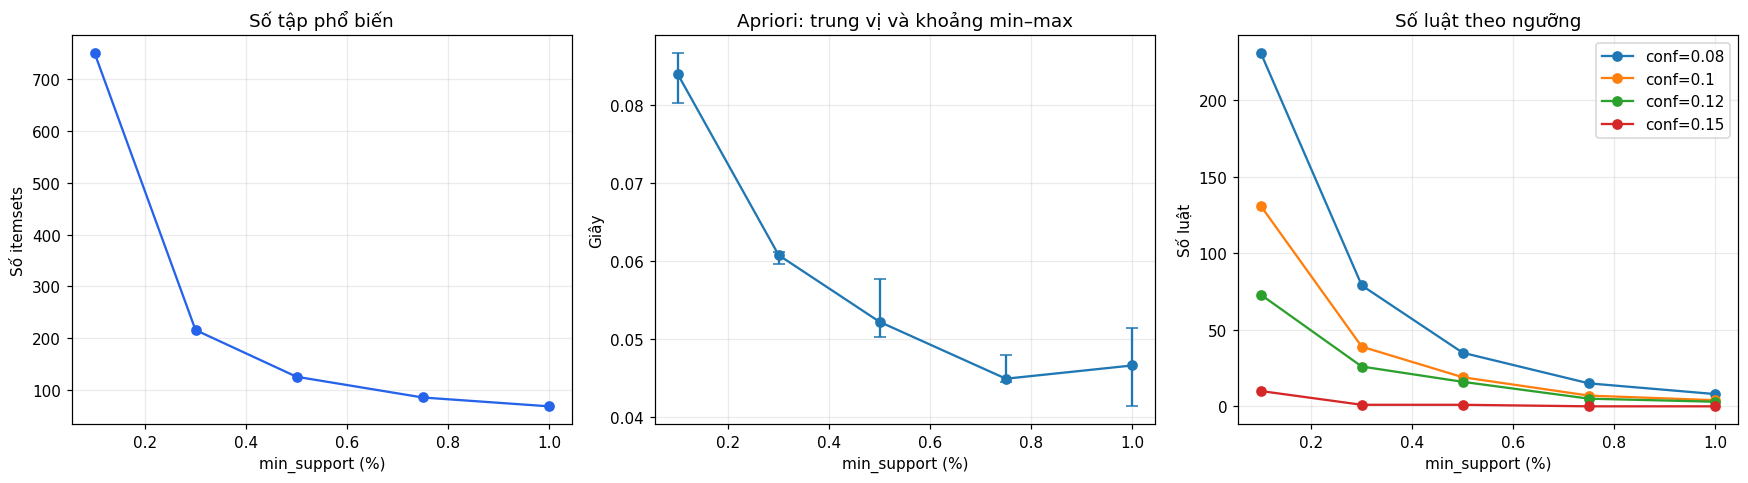

**Nhận xét:** Khi tăng support từ 0.001 lên 0.01, số tập phổ biến thay đổi từ 750 xuống 69. Thời gian Apriori trung vị tương ứng 0.0840s và 0.0466s. Tăng confidence tại một support cố định chỉ có thể giữ nguyên hoặc giảm số luật. Thời gian không bắt buộc biến thiên đơn điệu do nhiễu đo và chi phí xử lý từng lần.

,min_support,size,count
0,0.0010,1,149
1,0.0010,2,592
2,0.0010,3,9
3,0.0030,1,111
4,0.0030,2,105
5,0.0050,1,89
6,0.0050,2,37
7,0.0075,1,74
8,0.0075,2,12
9,0.0100,1,64


In [10]:
by_support = summary.drop_duplicates('min_support').sort_values('min_support')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = by_support['min_support'] * 100
axes[0].plot(x, by_support['frequent_itemsets'], 'o-', color='#2563eb')
axes[0].set(title='Số tập phổ biến', ylabel='Số itemsets')
axes[1].errorbar(x, by_support['apriori_s_median'],
    yerr=[by_support['apriori_s_median']-by_support['apriori_s_min'],
          by_support['apriori_s_max']-by_support['apriori_s_median']], fmt='o-', capsize=4)
axes[1].set(title='Apriori: trung vị và khoảng min–max', ylabel='Giây')
for confidence in CONFIDENCES:
    part = summary[summary['min_confidence'].eq(confidence)].sort_values('min_support')
    axes[2].plot(part['min_support'] * 100, part['rules'], 'o-', label=f'conf={confidence:g}')
axes[2].set(title='Số luật theo ngưỡng', ylabel='Số luật')
axes[2].legend()
for ax in axes:
    ax.set_xlabel('min_support (%)')
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / '01_AnhHuongNguong.png', bbox_inches='tight')
plt.show()
lo, hi = by_support.iloc[0], by_support.iloc[-1]
nhan_xet(f'Khi tăng support từ {lo.min_support:g} lên {hi.min_support:g}, '
         f'số tập phổ biến thay đổi từ {int(lo.frequent_itemsets)} xuống {int(hi.frequent_itemsets)}. '
         f'Thời gian Apriori trung vị tương ứng {lo.apriori_s_median:.4f}s và {hi.apriori_s_median:.4f}s. '
         'Tăng confidence tại một support cố định chỉ có thể giữ nguyên hoặc giảm số luật. '
         'Thời gian không bắt buộc biến thiên đơn điệu do nhiễu đo và chi phí xử lý từng lần.')

size_rows = [{'min_support': s, 'size': k, 'count': int(v)}
             for s, f in frequent_by_support.items()
             for k, v in f['itemsets'].map(len).value_counts().sort_index().items()]
size_distribution = pd.DataFrame(size_rows, columns=['min_support', 'size', 'count'])
display(size_distribution)


## 8. Phân tích một cấu hình và Top luật
Mặc định xem `support=0.003, confidence=0.10`; có thể thay bằng một cặp đã chạy. Đây là cấu hình minh họa, **không gọi là tối ưu** khi chưa kiểm tra trên dữ liệu mới hoặc đánh giá nghiệp vụ.

Hiển thị cả Top luật theo confidence và nhóm luật có lift > 1. Với kiểm tra “confidence tương đối cao nhưng lift gần 1”, dùng quy ước rõ ràng: confidence ≥ 0.15 và |lift − 1| ≤ 0.05. Đây chỉ là ngưỡng minh họa cho bài phân tích.


In [11]:
SELECT_SUPPORT = 0.003
SELECT_CONFIDENCE = 0.10
if (SELECT_SUPPORT, SELECT_CONFIDENCE) not in rules_by_config:
    raise ValueError('Chọn support/confidence trong các ngưỡng đã chạy.')
selected_freq = frequent_by_support[SELECT_SUPPORT]
selected_rules = rules_by_config[(SELECT_SUPPORT, SELECT_CONFIDENCE)]
selected_table = readable_rules(selected_rules)
print('Top tập phổ biến:')
display(readable_itemsets(selected_freq).sort_values('support', ascending=False).head(15))
print('Top luật theo confidence (chưa lọc lift):')
display(selected_table.sort_values(['confidence', 'lift'], ascending=False).head(10).round(6))
positive = selected_table[selected_table['lift'].gt(1)].sort_values(
    ['lift', 'support', 'confidence'], ascending=False)
print('Luật có lift > 1 trong cấu hình đã chọn:')
display(positive.head(10).round(6))
if selected_table.empty:
    nhan_xet('Không có luật thỏa cấu hình này. Đây là kết quả hợp lệ; xem dải ngưỡng thấp hơn, '
             'không tự tạo luật hoặc kết luận thuật toán bị lỗi.')
else:
    row = selected_table.sort_values(['confidence', 'lift'], ascending=False).iloc[0]
    nhan_xet(f'Luật {row.antecedents} → {row.consequents} có support={row.support:.4%}, '
             f'tức {row.cooccurrence_count} trên {N:,} giỏ chứa cả hai vế; '
             f'confidence={row.confidence:.2%}; lift={row.lift:.3f}. '
             f'Có {len(positive)} luật với lift > 1 trong tổng {len(selected_table)} luật. '
             'Nếu lift ≤ 1, confidence đơn lẻ không đủ để chọn làm gợi ý mua kèm.')

# Dùng toàn bộ luật đã khai thác để tìm ví dụ, loại sự lặp giữa các cấu hình.
all_rules = pd.concat([readable_rules(r) for r in rules_by_config.values()], ignore_index=True)
all_rules = all_rules.drop_duplicates(['antecedents', 'consequents']).reset_index(drop=True)
near_independent = all_rules[(all_rules['confidence'] >= 0.15) &
                             ((all_rules['lift'] - 1).abs() <= 0.05)]
print('Confidence ≥ 0.15 và lift trong [0.95, 1.05]:')
display(near_independent.sort_values('confidence', ascending=False).head(10).round(6))
if near_independent.empty:
    nhan_xet('Không tìm thấy luật đáp ứng đồng thời định nghĩa minh họa trên trong lưới đã thử. '
             'Không có ví dụ phù hợp cũng là một kết quả cần báo cáo.')
else:
    nhan_xet('Các luật trên có confidence tương đối cao trong dải đang thử, nhưng lift gần 1. '
             'Xác suất có sản phẩm ở vế phải gần mức phổ biến sẵn có của chính sản phẩm đó.')


Top tập phổ biến:


,support,itemsets,count,size
108,0.157923,whole milk,2363,1
67,0.122101,other vegetables,1827,1
82,0.110005,rolls/buns,1646,1
91,0.097106,soda,1453,1
109,0.085879,yogurt,1285,1
83,0.069572,root vegetables,1041,1
101,0.067767,tropical fruit,1014,1
7,0.060683,bottled water,908,1
86,0.060349,sausage,903,1
22,0.053131,citrus fruit,795,1


Top luật theo confidence (chưa lọc lift):


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,cooccurrence_count
2,bottled beer,whole milk,0.045312,0.157923,0.007151,0.157817,0.999330,107
32,sausage,whole milk,0.060349,0.157923,0.008955,0.148394,0.939663,134
21,newspapers,whole milk,0.038896,0.157923,0.005614,0.144330,0.913926,84
12,domestic eggs,whole milk,0.037091,0.157923,0.005280,0.142342,0.901341,79
19,hamburger meat,whole milk,0.021854,0.157923,0.003074,0.140673,0.890769,46
14,frankfurter,whole milk,0.037760,0.157923,0.005280,0.139823,0.885388,79
0,beef,whole milk,0.033950,0.157923,0.004678,0.137795,0.872548,70
13,frankfurter,other vegetables,0.037760,0.122101,0.005146,0.136283,1.116150,77
16,frozen vegetables,whole milk,0.028002,0.157923,0.003809,0.136038,0.861422,57
29,pork,whole milk,0.037091,0.157923,0.005012,0.135135,0.855703,75


Luật có lift > 1 trong cấu hình đã chọn:


...

**Nhận xét:** Luật bottled beer → whole milk có support=0.7151%, tức 107 trên 14,963 giỏ chứa cả hai vế; confidence=15.78%; lift=0.999. Có 2 luật với lift > 1 trong tổng 39 luật. Nếu lift ≤ 1, confidence đơn lẻ không đủ để chọn làm gợi ý mua kèm.

Confidence ≥ 0.15 và lift trong [0.95, 1.05]:


/tmp/ipykernel_466/3514130603.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_rules = pd.concat([readable_rules(r) for r in rules_by_config.values()], ignore_index=True)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,cooccurrence_count
62,detergent,whole milk,0.008621,0.157923,0.001403,0.162791,1.030824,21
89,ham,whole milk,0.017109,0.157923,0.002740,0.160156,1.014142,41
13,bottled beer,whole milk,0.045312,0.157923,0.007151,0.157817,0.999330,107
73,frozen fish,whole milk,0.006817,0.157923,0.001069,0.156863,0.993287,16


**Nhận xét:** Các luật trên có confidence tương đối cao trong dải đang thử, nhưng lift gần 1. Xác suất có sản phẩm ở vế phải gần mức phổ biến sẵn có của chính sản phẩm đó.

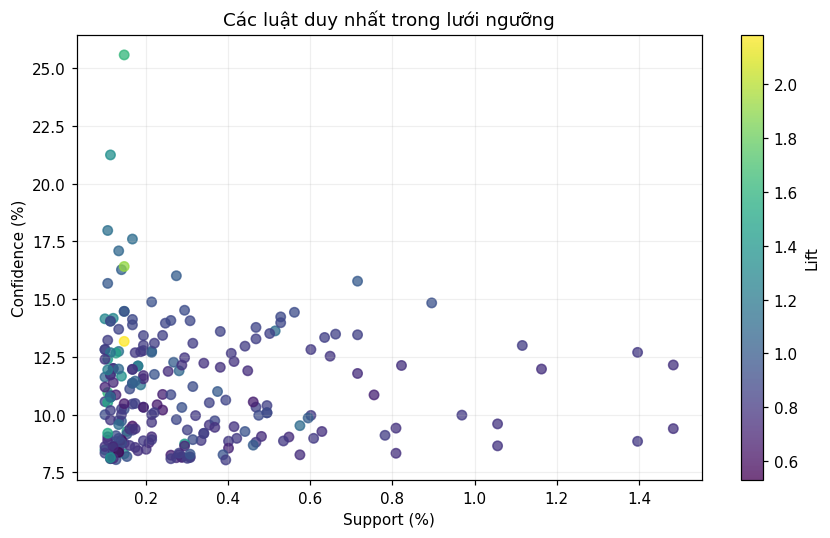

In [12]:
if not all_rules.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    points = ax.scatter(all_rules['support']*100, all_rules['confidence']*100,
                        c=all_rules['lift'], cmap='viridis', s=38, alpha=.75)
    fig.colorbar(points, ax=ax, label='Lift')
    ax.set(xlabel='Support (%)', ylabel='Confidence (%)',
           title='Các luật duy nhất trong lưới ngưỡng')
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT / '02_SupportConfidenceLift.png', bbox_inches='tight')
    plt.show()
else:
    print('Không có luật để vẽ biểu đồ support–confidence.')
